##  Simple Transport between graphs using FGW

This notebook proposes to compute the assignment of labeled graphs using FGW

In [1]:
import numpy as np
import os,sys
sys.path.append(os.path.realpath('../lib'))
from graph_sentence_temporal import graph_colors,draw_rel,draw_transp,Graph,wl_labeling
from ot_distances import Fused_Gromov_Wasserstein_distance,Wasserstein_distance
import copy
from data_loader import load_local_data,histog,build_noisy_circular_graph
import matplotlib.pyplot as plt
import networkx as nx
from sentence_transformers import SentenceTransformer

c:\Users\lucie\OneDrive\Documents\TrustCalibration\FGW\.venv3\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


First example is a transport between two simple graphs with four nodes

In [2]:
method='harmonic_distance'
embedding = SentenceTransformer('all-MiniLM-L6-v2')
print("add sentences")
g1=Graph()
g1.add_sentence("{f: scared}[exhales sharply] No... do {g: Shaking Head No}do NOT {t: Negation} take the left road.",embedding)
g2=Graph()
g2.add_sentence("{f: confidence}  Hmm... {g: Talking 2} I'm pretty sure it's the enigmatic [thoughtful] civilization of Xeridora! ",embedding)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 9403.86it/s]


add sentences
intervening_text:  0
intervening_text:  0
intervening_text: no do 2
intervening_text: do not 2
Processing event: type=f, value=scared, gap=0, state={'f': None, 'g': None, 'i': None, 't': None}, expirations={'f': inf, 'g': 0, 'i': 0, 't': 0}
Processing event: type=i, value=exhales sharply, gap=0, state={'f': 'scared', 'g': None, 'i': None, 't': None}, expirations={'f': inf, 'g': 0, 'i': 0, 't': 0}
Processing event: type=g, value=Shaking Head No, gap=2, state={'f': 'scared', 'g': None, 'i': 'exhales sharply', 't': None}, expirations={'f': inf, 'g': 0, 'i': 1, 't': 0}
node_during_gap: 0 state: {'f': 'scared', 'g': None, 'i': 'exhales sharply', 't': None}
expiration node_during_gap: 1 state: {'f': 'scared', 'g': None, 'i': None, 't': None}
Processing event: type=t, value=Negation, gap=2, state={'f': 'scared', 'g': 'Shaking Head No', 'i': None, 't': None}, expirations={'f': inf, 'g': 5, 'i': 1, 't': 0}
node_during_gap: 2 state: {'f': 'scared', 'g': 'Shaking Head No', 'i': None

In [3]:
from sentence_transformers import SentenceTransformer

# 1. Load the pre-trained model
# This model is a great balance of speed and accuracy
model = SentenceTransformer('all-MiniLM-L6-v2')

# 2. Your node descriptions
# These are the annotations you have for each node in your graph
node_descriptions = [
    "happy smiling face", 
    "slight smile with closed eyes", 
    "angry furrowed brow", 
    "aggressive hand gesture waving",
    "annoyed head nod"
]

# 3. Generate Embeddings (The "Zero-Shot" part)
# The model converts each text description into a 384-dimensional vector
embeddings = model.encode(node_descriptions)

# Now you have a matrix of shape (5, 384)
# This matrix is exactly what you pass into the 'emb' part of the FGW distance!

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6286.76it/s]


0 -1
1 3
2 0
3 0


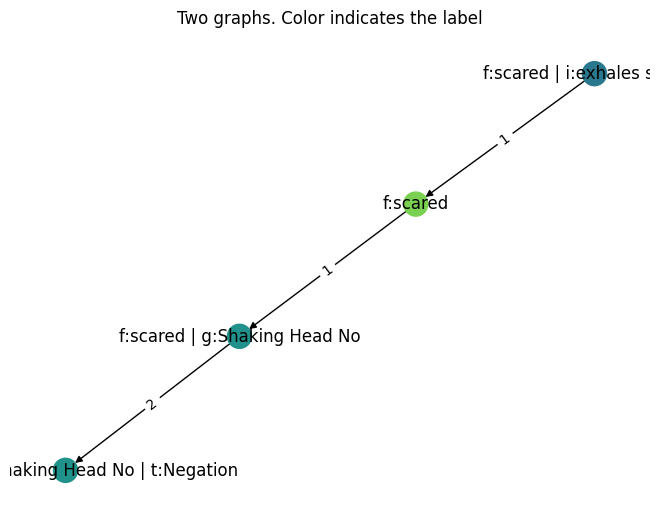

In [4]:
#plt.figure(figsize=(5,4))
vmin=0
vmax=7
draw_rel(g1.nx_graph,draw=False,vmin=-5,vmax=5,with_labels=True)
#draw_rel(g2.nx_graph,draw=False,vmin=-5,vmax=5,with_labels=True,shiftx=5,swipy=True)
plt.title('Two graphs. Color indicates the label')
plt.show()

In [5]:
sample_text = "Hello {f: smile} how are you [excited] {g: Shaking Head No} and how is {t: Negation} it going {f: neutral} {g: Talking 2}"
gif_path = g1.create_sentence_gif(sample_text)
print(f"Animation successfully created at: {gif_path}")

0 -1
0 0
1 0
2 1
3 2
3 3
3 3
4 3
5 4
6 5
6 6
7 6
8 7
8 8
8 8
Animation successfully created at: gesture_animation.gif


In [6]:
alpha=0.5
dfgw=Fused_Gromov_Wasserstein_distance(alpha=alpha,features_metric='sqeuclidean',method=method).graph_d(g1,g2)
dw=Wasserstein_distance(features_metric='sqeuclidean').graph_d(g1,g2)
dgw=Fused_Gromov_Wasserstein_distance(alpha=1,features_metric='sqeuclidean',method=method).graph_d(g1,g2)
print('Wasserstein distance={}, Gromov distance={} \nFused Gromov-Wasserstein distance for alpha {} = {}'.format(dw,dgw,alpha,dfgw))

[[ 0.          0.25        0.5         0.375     ]
 [ 1.75        0.          0.25        0.12500006]
 [ 1.5         1.75        0.         -0.12499994]
 [ 0.62500003  0.875       1.125       0.        ]]
[[ 0.          0.33333337  0.11111111]
 [ 1.66666675  0.         -0.2222222 ]
 [ 0.22222222  0.5555556   0.        ]]
Wasserstein distance=0.6667831763625145, Gromov distance=0.4672237614325403 
Fused Gromov-Wasserstein distance for alpha 0.5 = 0.47368129466842834


We see that neither Wasserstein distance on the label, or Gromov distance can discriminate between this two graphs, whereas FGW does not vanish.

We now build more complicated graphs with the following :

In [7]:
def build_comunity_graph(N=30,mu=0,sigma=0.3,pw=0.8):
    v=mu+sigma*np.random.randn(N);
    g=Graph()
    g.add_nodes(list(range(N)))
    for i in range(N):
         g.add_one_attribute(i,embeddings[i])
         for j in range(N):
             r=np.random.rand()
             if  r<pw:
                 g.add_edge((i,j),time=int(r*10))
    return g


We plot the evolution of the FGW distance with respect to the alpha parameter

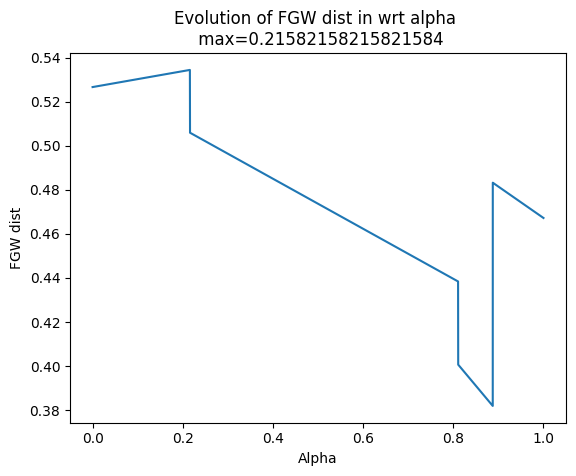

In [8]:
alld=[]
x=np.linspace(0,1,10000)
for alpha in x:
    d=Fused_Gromov_Wasserstein_distance(alpha=alpha,features_metric='sqeuclidean',method=method).graph_d(g1,g2)
    alld.append(d)
plt.plot(x,alld)
plt.title('Evolution of FGW dist in wrt alpha \n max={}'.format(x[np.argmax(alld)]))
plt.xlabel('Alpha')
plt.ylabel('FGW dist')
plt.show()

We see that the alpha which leads to best discriminate the graphs is between 0 and 1. We plot the coupling using this alpha :

0 -1
1 3
2 0
3 0
0 2
1 -1
2 -2


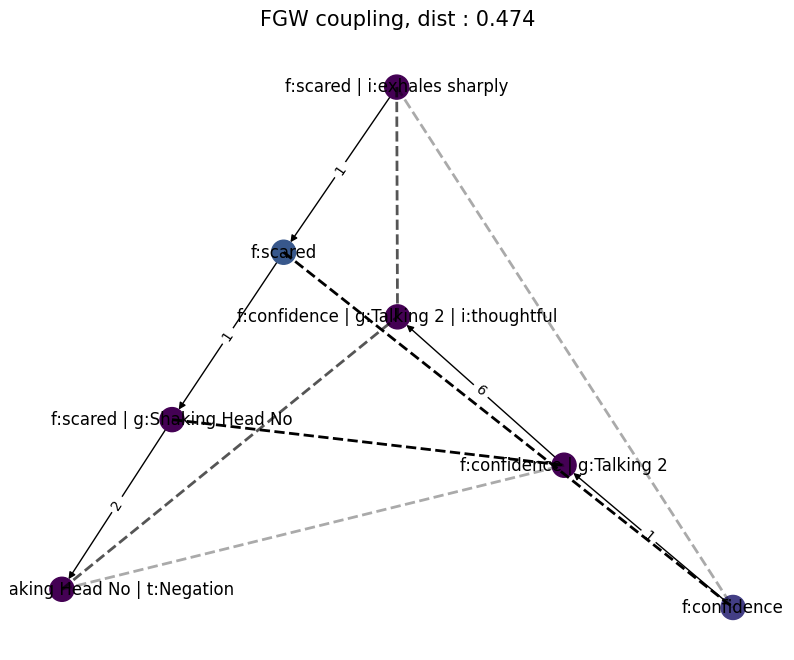

In [9]:
fig=plt.figure(figsize=(10,8))
thresh=0.004
gwdist=Fused_Gromov_Wasserstein_distance(alpha=0.5,features_metric='sqeuclidean',method=method)
d=gwdist.graph_d(g1,g2)
plt.title('FGW coupling, dist : '+str(np.round(d,3)),fontsize=15)
draw_transp(g1,g2,gwdist.transp,shiftx=2,shifty=0.5,thresh=thresh,
            swipy=True,swipx=False,with_labels=True,vmin=vmin,vmax=11)
plt.show()

We can also plot the GW coupling

0 -1
1 3
2 0
3 0
0 2
1 -1
2 -2


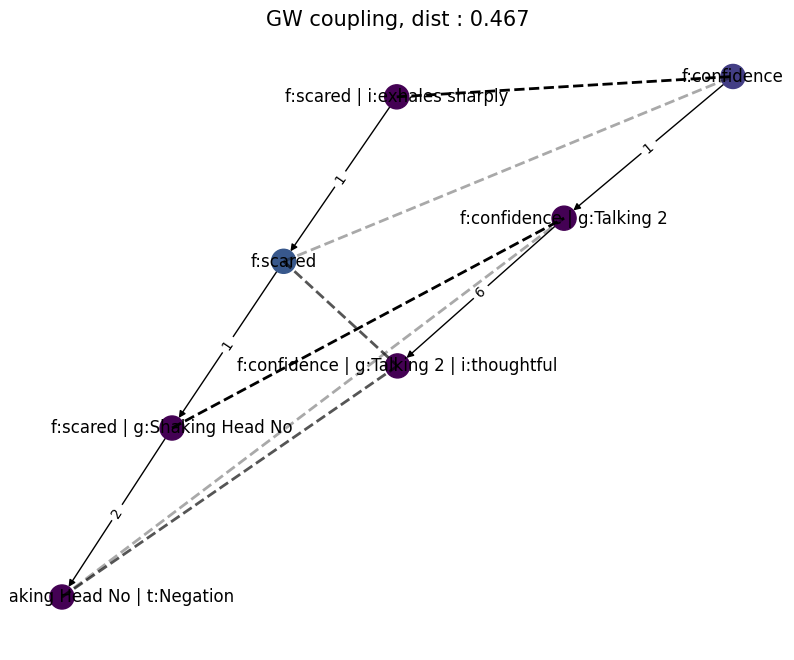

In [10]:
fig=plt.figure(figsize=(10,8))
thresh=0.004
gwdist=Fused_Gromov_Wasserstein_distance(alpha=1,features_metric='sqeuclidean',method=method)
d=gwdist.graph_d(g1,g2)
plt.title('GW coupling, dist : '+str(np.round(d,3)),fontsize=15)
draw_transp(g1,g2,gwdist.transp,shiftx=2,shifty=0.5,thresh=thresh,
            swipy=False,swipx=False,with_labels=True,vmin=vmin,vmax=11)

plt.show()